In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [21]:
pd.set_option('display.precision',2)
plt.rcParams['font.family']='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['axes.grid'] = True

In [5]:
CM = '23_cmapss_fd001_sample.csv'
CM_unit1 = '23_cmapss_unit1_timestamp.csv'
PL = '23_전기Panel.csv'

In [4]:
# 절대값의 함정을 이해하고, 추세와 변동성이라는 두 흔적을 파악한다.
# ex 1

In [6]:
df = pd.read_csv(PL)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1250 entries, 0 to 1249
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   설비번호    1250 non-null   int64  
 1   시퀀스     1250 non-null   int64  
 2   컨베이어전류  1250 non-null   float64
 3   회전A전류   1250 non-null   float64
 4   회전B전류   1250 non-null   float64
 5   펌프A전류   1250 non-null   float64
 6   펌프B전류   1250 non-null   float64
dtypes: float64(5), int64(2)
memory usage: 68.5 KB


In [8]:
df['설비번호'].unique()

array([1, 2, 3, 4, 5])

In [12]:
u2 = df[df['설비번호'] == 2].copy().sort_values('시퀀스').reset_index(drop=True)

In [13]:
u2.shape

(250, 7)

In [20]:
u2.index

RangeIndex(start=0, stop=250, step=1)

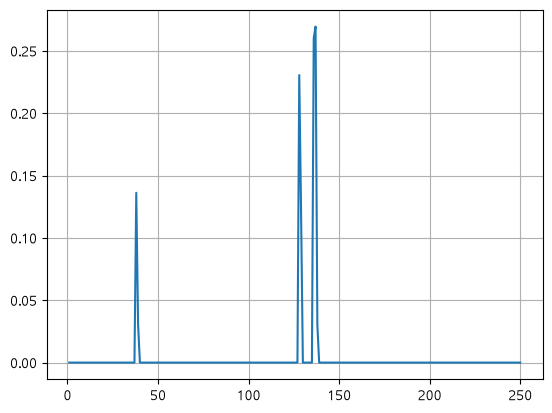

In [22]:
plt.plot(
    u2['시퀀스'],
    u2['컨베이어전류']
)

# plt.legend()
plt.show()

In [23]:
u2['ma10'] = u2['컨베이어전류'].rolling(10).mean()

In [24]:
u2.head()

,설비번호,시퀀스,컨베이어전류,회전A전류,회전B전류,펌프A전류,펌프B전류,ma10
0,2,1,0.0,0.05,0.7,0.0,0.0,NaN
1,2,2,0.0,0.05,0.7,0.0,0.0,NaN
2,2,3,0.0,0.05,0.7,0.0,0.0,NaN
3,2,4,0.0,0.05,0.7,0.0,0.0,NaN
4,2,5,0.0,0.05,0.7,0.0,0.0,NaN


In [26]:
u2['ma10'].head(11).to_list()

[nan, nan, nan, nan, nan, nan, nan, nan, nan, 0.0, 0.0]

In [27]:
resid1 = u2['컨베이어전류'] - u2['ma10']

In [ ]:
# 임계치 잡는법

In [28]:
thr1 = 2*resid1.std()

In [29]:
resid1.abs() > thr1

0      False
1      False
2      False
3      False
4      False
       ...  
245    False
246    False
247    False
248    False
249    False
Length: 250, dtype: bool

In [30]:
resid1[resid1.abs() > thr1]

37     0.12
127    0.21
128    0.09
135    0.20
136    0.18
138   -0.06
139   -0.06
140   -0.06
141   -0.06
142   -0.06
143   -0.06
144   -0.06
dtype: float64

In [31]:
len(resid1[resid1.abs() > thr1])

12

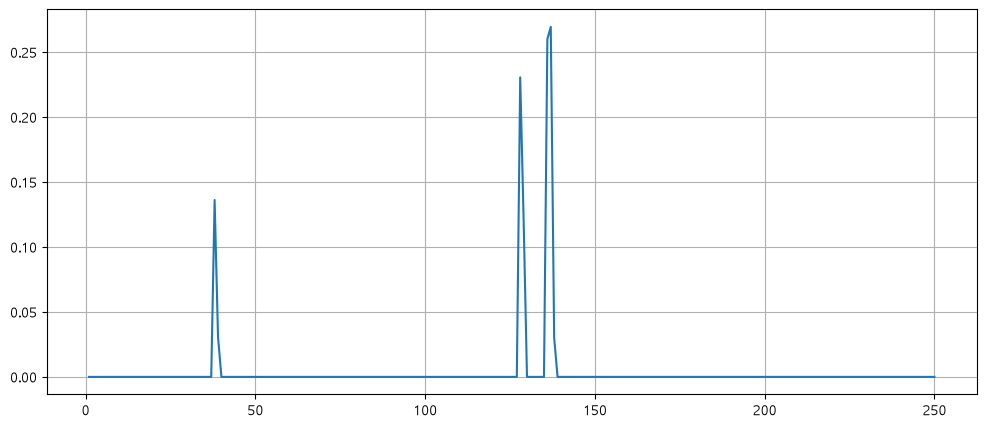

In [35]:
plt.figure(figsize=(12,5))

plt.plot(
    u2['시퀀스'],
    u2['컨베이어전류']
)

# plt.legend()
plt.show()


# 상단의 수치를 그레프에서 확인가능

In [48]:
# RStudio 파이선 변환

                            OLS Regression Results                            
Dep. Variable:                  sales   R-squared:                       0.788
Model:                            OLS   Adj. R-squared:                  0.772
Method:                 Least Squares   F-statistic:                     48.44
Date:                Thu, 05 Nov 2026   Prob (F-statistic):           9.92e-06
Time:                        11:17:54   Log-Likelihood:                -46.146
No. Observations:                  15   AIC:                             96.29
Df Residuals:                      13   BIC:                             97.71
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         62.9291      5.374     11.710      0.0

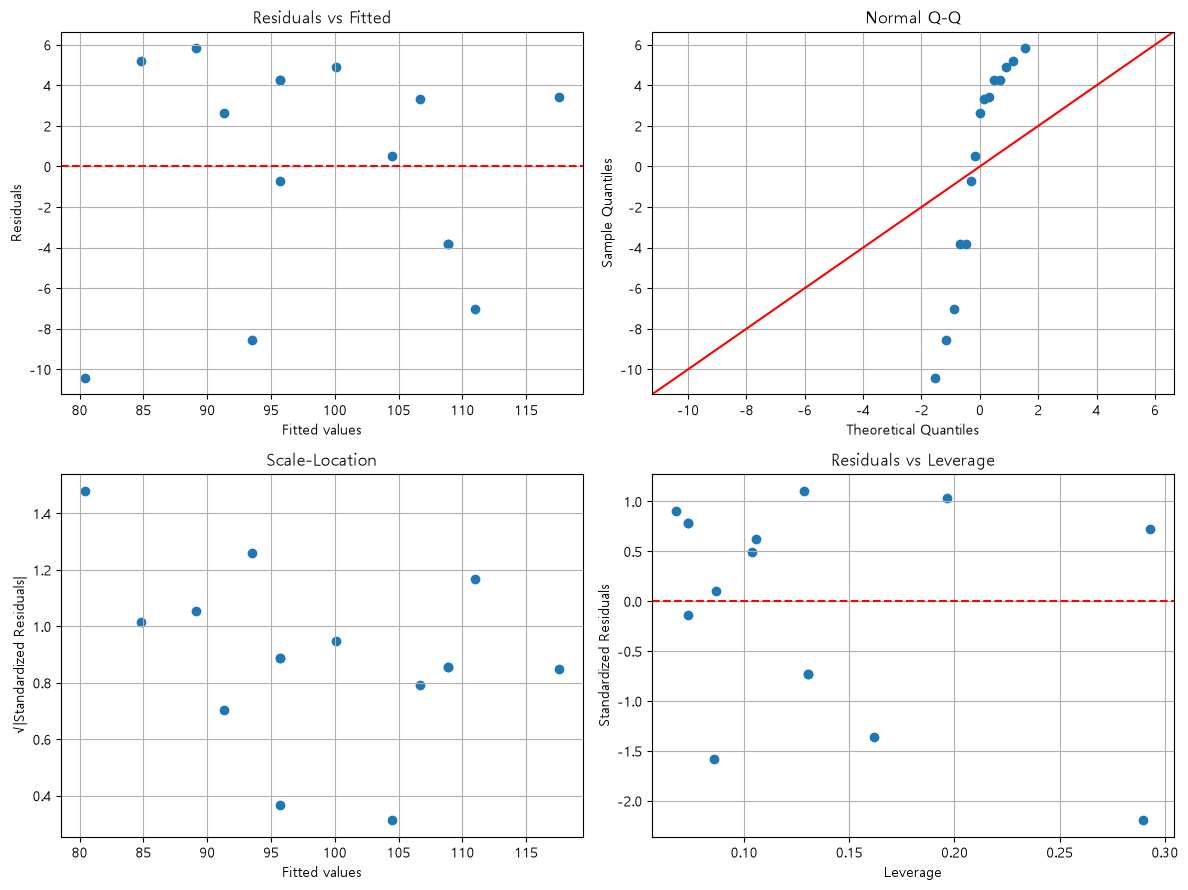

In [53]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
import statsmodels.api as sm

# 1. 데이터 입력
sales = [94, 70, 90, 100, 95, 100, 85, 95, 105, 105,
         110, 105, 104, 105, 121]

ad = [13, 8, 10, 15, 12, 15, 14, 15, 17, 19,
      20, 21, 22, 21, 25]

# 2. 데이터프레임 생성
df = pd.DataFrame({
    'sales': sales,
    'ad': ad
})

# 3. 독립변수와 종속변수 설정
X = df['ad']
y = df['sales']

# 4. 상수항 추가
X = sm.add_constant(X)

# 5. 선형회귀모델 생성
lin_model = sm.OLS(y, X).fit()

# 6. 회귀분석 결과 확인
print(lin_model.summary())

# 7. 회귀분석 그래프

# 2행 2열 그래프 생성
fig, ax = plt.subplots(2, 2, figsize=(12, 9))

# ① Residuals vs Fitted
ax[0, 0].scatter(lin_model.fittedvalues, lin_model.resid)
ax[0, 0].axhline(y=0, color='red', linestyle='--')
ax[0, 0].set_title('Residuals vs Fitted')
ax[0, 0].set_xlabel('Fitted values')
ax[0, 0].set_ylabel('Residuals')

# ② Normal Q-Q
sm.qqplot(
    lin_model.resid,
    line='45',
    ax=ax[0, 1]
)
ax[0, 1].set_title('Normal Q-Q')

# ③ Scale-Location
ax[1, 0].scatter(
    lin_model.fittedvalues,
    abs(lin_model.get_influence().resid_studentized_internal) ** 0.5
)
ax[1, 0].set_title('Scale-Location')
ax[1, 0].set_xlabel('Fitted values')
ax[1, 0].set_ylabel('√|Standardized Residuals|')

# ④ Residuals vs Leverage
influence = lin_model.get_influence()

ax[1, 1].scatter(
    influence.hat_matrix_diag,
    influence.resid_studentized_internal
)
ax[1, 1].axhline(y=0, color='red', linestyle='--')
ax[1, 1].set_title('Residuals vs Leverage')
ax[1, 1].set_xlabel('Leverage')
ax[1, 1].set_ylabel('Standardized Residuals')

plt.tight_layout()
plt.show()


# plt.figure(figsize=(10, 6))

# plt.scatter(df['ad'], df['sales'], label='Actual Data')

# plt.plot(
#     df['ad'],
#     lin_model.predict(X),
#     color='red',
#     label='Regression Line'
# )

# plt.xlabel('Advertising')
# plt.ylabel('Sales')
# plt.title('Linear Regression: Sales ~ Ad')
# plt.legend()
# plt.grid(True)

# plt.show()

In [37]:
# ex 2
# 이동평균 추적하기
# 원본위에 rolling 값 얹어 비교하기

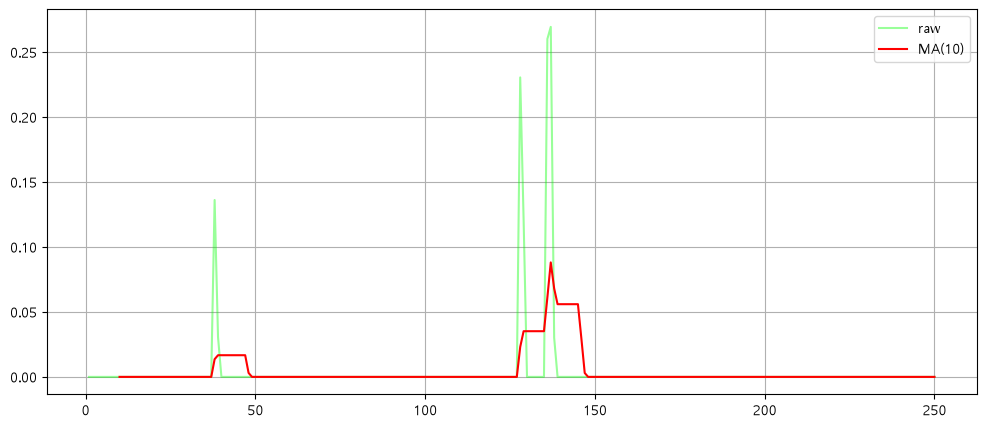

In [42]:
plt.figure(figsize=(12,5))

plt.plot(
    u2['시퀀스'],
    u2['컨베이어전류'],
    color='#00ff00',
    label='raw',
    alpha=0.4
)

plt.plot(
    u2['시퀀스'],
    u2['ma10'],
    color='#ff0000',
    label='MA(10)'
)


plt.legend()
plt.show()

In [44]:
# ex 3
# rolling 단위를 바꿔가며 비교 분석

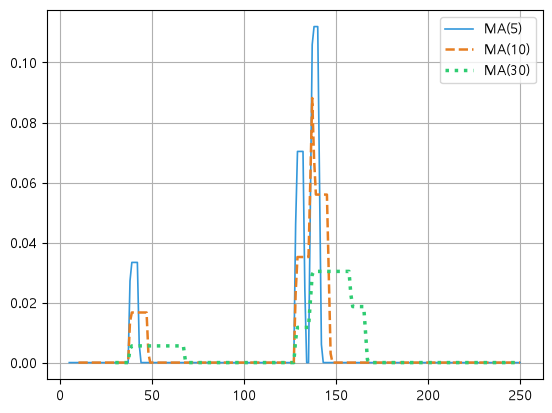

In [47]:
colors = ['#3498DB', '#E67E22', '#2ECC71']
styles = ['-', '--', ':']
widths = [1.2, 1.8, 2.5]

for w, c, s, lw in zip([5, 10, 30], colors, styles, widths):

    u2[f'ma{w}'] = u2['컨베이어전류'].rolling(w).mean()

    plt.plot(
        u2['시퀀스'],
        u2[f'ma{w}'],
        label=f'MA({w})',
        color=c,
        linestyle=s,
        linewidth=lw
    )

plt.legend()
plt.show()

In [54]:
# ex 4

In [55]:
u2['ma10'] = u2['컨베이어전류'].rolling(10).mean()
u2['std10'] = u2['컨베이어전류'].rolling(10).std()

In [56]:
u2['std10'].iloc[10:50].mean()

np.float64(0.0110137344691303)

In [58]:
el = u2['std10'].iloc[10:50].mean()

la = u2['std10'].iloc[150:].mean()

In [57]:
u2['std10'].iloc[150:].mean()

np.float64(0.0)

In [ ]:
# ex 5

# 연속시점의 변화량과 이동평균의 변화량을 비교

In [62]:
u2['diff'] = u2['컨베이어전류'].diff()

u2['diff'].head().to_list()

[nan, 0.0, 0.0, 0.0, 0.0]

In [71]:
u2['시퀀스']

0        1
1        2
2        3
3        4
4        5
      ... 
245    246
246    247
247    248
248    249
249    250
Name: 시퀀스, Length: 250, dtype: int64

In [64]:
u2['diff'].abs().idxmax()

135

In [65]:
u2['diff'].abs().max()

np.float64(0.2602)

In [66]:
u2['ma_diff'] = u2['ma10'].diff()

In [69]:
u2['ma_diff'].to_list()

[nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.013619999999999998,
 0.0030700000000000015,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 -0.01362,
 -0.0030700000000000002,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.02306,
 0.012120000000000002,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.026019999999999995,
 0.026949999999999995,
 -0.02005,
 -0.012119999999999999,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,

In [72]:
# ex 6
# 단순 변화점 탐지 및 구간표기

In [73]:
roll = u2['컨베이어전류'].rolling(10).mean()

resid = u2['컨베이어전류'] - roll

thr = 2 * resid.std()

u2['is_change'] = resid.abs() > thr



In [76]:
thr.round(4)

np.float64(0.0536)

In [74]:
u2['is_change'].sum()

np.int64(12)

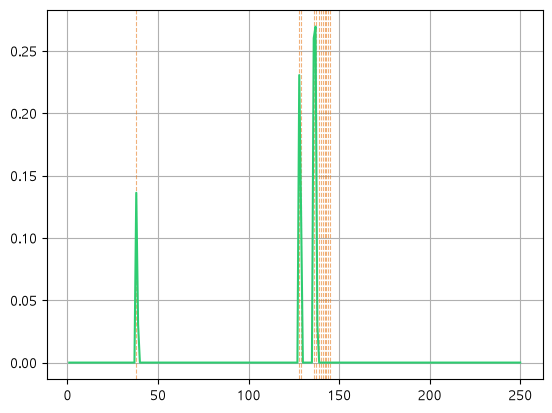

In [79]:
# colors = ['#3498DB', '#E67E22', '#2ECC71']


for c in u2.loc[u2['is_change'], '시퀀스']:
    plt.axvline(
        c,
        color='#E67E22',
        linestyle='--',
        alpha=0.6,
        linewidth= 0.8
    )

plt.plot(
    u2['시퀀스'],
    u2['컨베이어전류'],
    color='#2ECC71'
)    

plt.show()